<a href="https://colab.research.google.com/github/rama603/Reading-Sign-Language-/blob/main/Reading_Sign_Language%20stage%201.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load datasets
train_df = pd.read_csv("sign_mnist_train.csv")
test_df = pd.read_csv("sign_mnist_test.csv")

# Extract features and labels
X_train = train_df.drop(columns="label").values.astype("float32") / 255.0
y_train = train_df["label"].values

X_test = test_df.drop(columns="label").values.astype("float32") / 255.0
y_test = test_df["label"].values

print("Training data shape:", X_train.shape)
print("Test data shape:", X_test.shape)

Training data shape: (27455, 784)
Test data shape: (7172, 784)


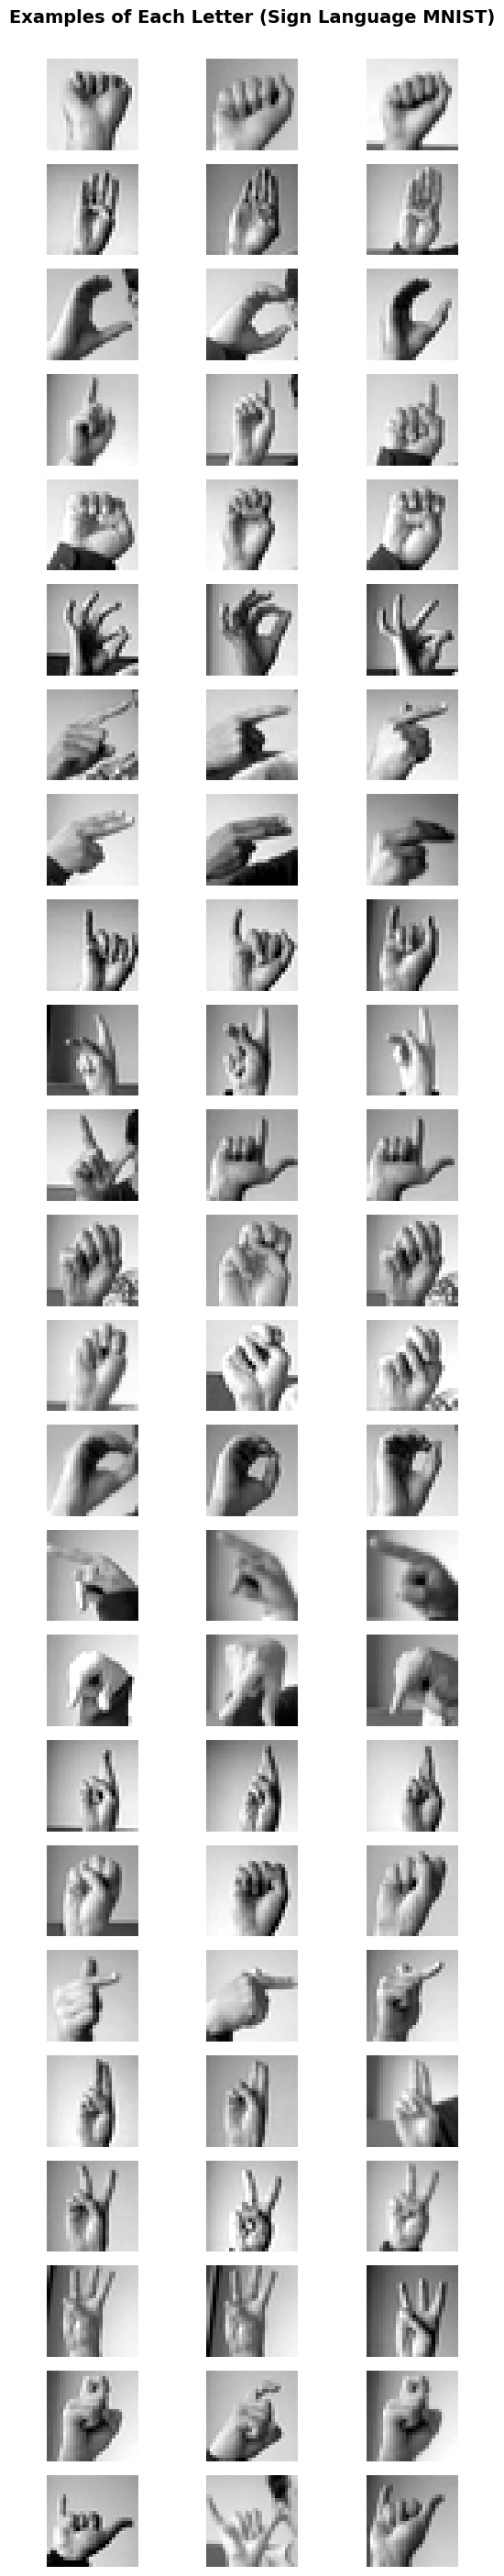

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# Map labels 0-24 to letters A-Y (skipping J which is index 9)
def get_letter(label):
    if label < 9:
        return chr(ord('A') + label)
    else:
        return chr(ord('A') + label + 1)

unique_labels = sorted(np.unique(y_train))
num_samples_per_letter = 3

fig, axes = plt.subplots(len(unique_labels), num_samples_per_letter, figsize=(6, 28))

for i, label in enumerate(unique_labels):
    letter = get_letter(label)
    idxs = np.where(y_train == label)[0]
    sample_idxs = idxs[:num_samples_per_letter] # Grab 3 examples for this letter

    for j, idx in enumerate(sample_idxs):
        ax = axes[i, j]
        ax.imshow(X_train[idx].reshape(28, 28), cmap='gray')
        ax.axis('off')
        # Label the first column with the letter name
        if j == 0:
            ax.set_ylabel(letter, rotation=0, fontsize=12, labelpad=15, va='center', fontweight='bold')

plt.suptitle("Examples of Each Letter (Sign Language MNIST)", y=1.002, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Set a fixed random seed for reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Create a validation split from the training data
# (Note: A random split causes some data leakage due to augmented near-duplicates)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=RANDOM_SEED
)

# Test several values of C (inverse of L2 regularization strength)
c_values = [0.001, 0.01, 0.1, 1.0, 10.0]
results_table = []

best_C = None
best_val_acc = 0.0
best_model = None

print("--- Tuning C on Validation Data ---")
for c in c_values:
    # Initialize softmax classifier (multinomial logistic regression)
    clf = LogisticRegression(
    solver='lbfgs', C=c, max_iter=1000, random_state=RANDOM_SEED
)
    clf.fit(X_tr, y_tr)

    val_acc = accuracy_score(y_val, clf.predict(X_val))
    test_acc = accuracy_score(y_test, clf.predict(X_test))

    results_table.append({"C": c, "Val Accuracy": val_acc, "Test Accuracy": test_acc})
    print(f"C={c:<6} | Val Accuracy: {val_acc:.4f} | Test Accuracy: {test_acc:.4f}")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_C = c
        best_model = clf

print(f"\nBest C chosen based on validation accuracy: {best_C}")

# Convert results to a DataFrame for your report table
df_results = pd.DataFrame(results_table)

--- Tuning C on Validation Data ---
C=0.001  | Val Accuracy: 0.6085 | Test Accuracy: 0.5170
C=0.01   | Val Accuracy: 0.8254 | Test Accuracy: 0.6608
C=0.1    | Val Accuracy: 0.9801 | Test Accuracy: 0.6934
C=1.0    | Val Accuracy: 0.9996 | Test Accuracy: 0.7001
C=10.0   | Val Accuracy: 0.9996 | Test Accuracy: 0.6997

Best C chosen based on validation accuracy: 1.0


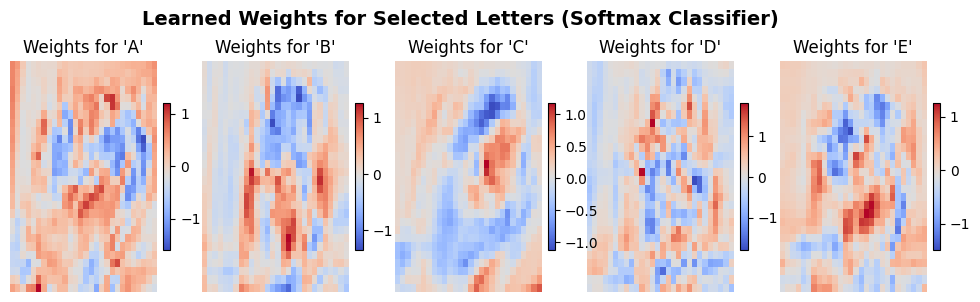

In [4]:
# Select 4-5 letters to visualize their weights
selected_letters = ['A', 'B', 'C', 'D', 'E']
fig, axes = plt.subplots(1, len(selected_letters), figsize=(12, 3))

for i, letter in enumerate(selected_letters):
    # Find the corresponding class label index (accounting for skipped J=9)
    label_idx = ord(letter) - ord('A')
    if label_idx >= 9:
        label_idx -= 1

    # Reshape the weight vector for this class back to 28x28
    class_weight = best_model.coef_[label_idx].reshape(28, 28)

    ax = axes[i]
    im = ax.imshow(class_weight, cmap='coolwarm', aspect='auto')
    ax.set_title(f"Weights for '{letter}'")
    ax.axis('off')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle("Learned Weights for Selected Letters (Softmax Classifier)", y=1.05, fontsize=14, fontweight='bold')
plt.show()

--- TOP 5 MOST CONFUSED LETTER PAIRS ---
True: V -> Predicted as W (80 times)
True: K -> Predicted as R (76 times)
True: R -> Predicted as U (60 times)
True: S -> Predicted as M (53 times)
True: Y -> Predicted as R (51 times)


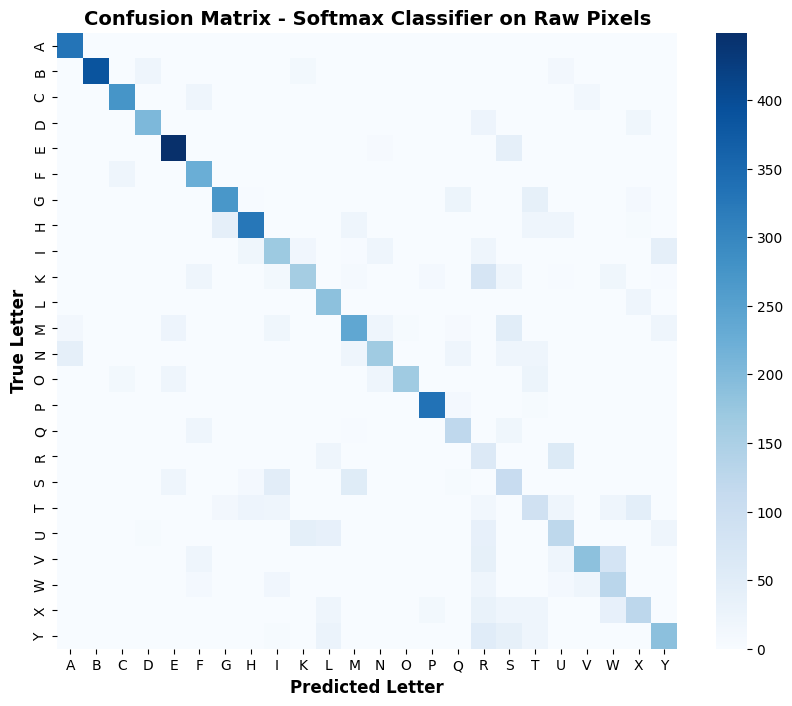


--- DISPLAYING EXAMPLE IMAGES FOR TOP 5 CONFUSED PAIRS ---

Displaying example images for True: 'V' -> Predicted: 'W' (Found 80 instances)


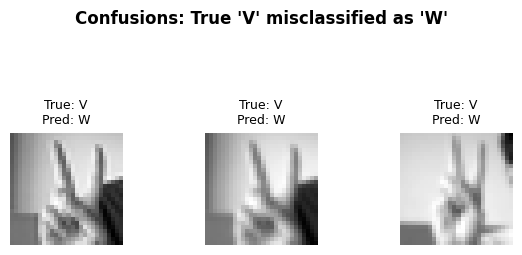


Displaying example images for True: 'K' -> Predicted: 'R' (Found 76 instances)


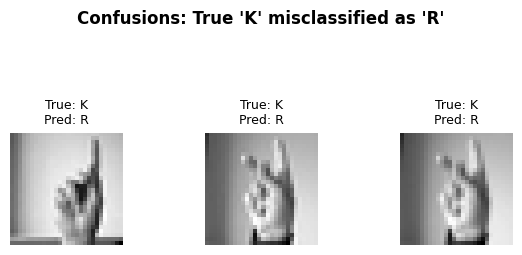


Displaying example images for True: 'R' -> Predicted: 'U' (Found 60 instances)


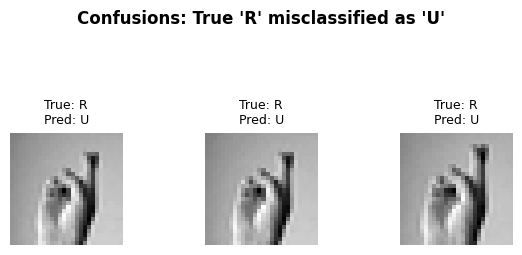


Displaying example images for True: 'S' -> Predicted: 'M' (Found 53 instances)


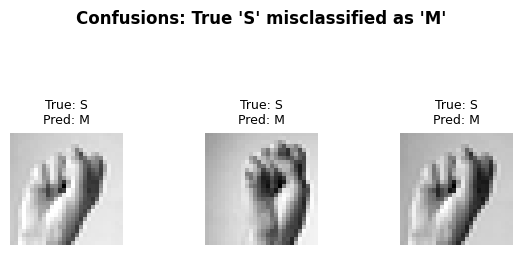


Displaying example images for True: 'Y' -> Predicted: 'R' (Found 51 instances)


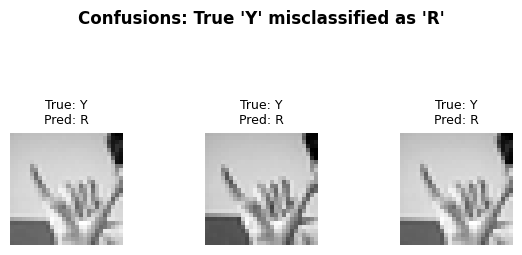

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Correct label-to-letter mapping for Sign Language MNIST
# (A-I are 0-8; K-Y are 10-24, since J=9 is skipped)
def get_letter(label):
    label = int(label)
    if label == 9:
        return 'J'
    return chr(ord('A') + label)

# 2. Get predictions and determine the exact unique labels present
final_test_preds = best_model.predict(X_test)
active_labels = sorted(np.unique(np.concatenate([y_test, final_test_preds])))
active_letters = [get_letter(l) for l in active_labels]

# 3. Compute confusion matrix using ONLY the active labels present in the data
cm = confusion_matrix(y_test, final_test_preds, labels=active_labels)

# 4. Find the top 5 most confused letter pairs (ignoring the diagonal)
cm_no_diag = cm.copy()
np.fill_diagonal(cm_no_diag, 0)
flat_idxs = np.argsort(cm_no_diag.ravel())[::-1]

print("--- TOP 5 MOST CONFUSED LETTER PAIRS ---")
top_confusions = []
count = 0
for idx in flat_idxs:
    if count >= 5:
        break
    r_idx, c_idx = np.unravel_index(idx, cm_no_diag.shape)
    if cm_no_diag[r_idx, c_idx] > 0:
        true_label_val = active_labels[r_idx]
        pred_label_val = active_labels[c_idx]

        true_let = get_letter(true_label_val)
        pred_let = get_letter(pred_label_val)
        freq = cm_no_diag[r_idx, c_idx]

        top_confusions.append({
            "True": true_let,
            "Pred": pred_let,
            "True_Val": true_label_val,
            "Pred_Val": pred_label_val,
            "Count": freq
        })
        print(f"True: {true_let} -> Predicted as {pred_let} ({freq} times)")
        count += 1

# 5. Plot the Confusion Matrix Heatmap with correct labels
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=False, fmt='d', cmap='Blues',
            xticklabels=active_letters, yticklabels=active_letters)
plt.xlabel("Predicted Letter", fontsize=12, fontweight='bold')
plt.ylabel("True Letter", fontsize=12, fontweight='bold')
plt.title("Confusion Matrix - Softmax Classifier on Raw Pixels", fontsize=14, fontweight='bold')
plt.show()

# 6. Display Example Images for ALL Top 5 Most Confused Pairs
print("\n--- DISPLAYING EXAMPLE IMAGES FOR TOP 5 CONFUSED PAIRS ---")
for pair in top_confusions:
    t_val = pair["True_Val"]
    p_val = pair["Pred_Val"]
    target_true_let = pair["True"]
    target_pred_let = pair["Pred"]
    freq = pair["Count"]

    mask = (y_test == t_val) & (final_test_preds == p_val)
    indices = np.where(mask)[0]

    print(f"\nDisplaying example images for True: '{target_true_let}' -> Predicted: '{target_pred_let}' (Found {len(indices)} instances)")

    if len(indices) > 0:
        fig, axes = plt.subplots(1, min(3, len(indices)), figsize=(6, 2))
        if len(indices) == 1:
            axes = [axes]

        for j, idx in enumerate(indices[:3]):
            axes[j].imshow(X_test[idx].reshape(28, 28), cmap='gray')
            axes[j].set_title(f"True: {target_true_let}\nPred: {target_pred_let}", fontsize=9)
            axes[j].axis('off')

        plt.suptitle(f"Confusions: True '{target_true_let}' misclassified as '{target_pred_let}'", y=1.25, fontsize=12, fontweight='bold')
        plt.tight_layout()
        plt.show()